# From a PD to capital: the IRB function, the large homogeneous portfolio and the TTC portfolio

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 05 of this topic (a PD by grade and the price of a calibration)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the large homogeneous portfolio (LHP) is, and read its distribution, its quantiles and the factor an observed default rate implies;
- take one exposure through the Basel III IRB function with every intermediate printed (the asset correlation, the 99.9% conditional PD, the maturity adjustment, K and the risk weight), and check it against the LHP quantile;
- compare four regulatory regimes on the same exposure and say which of their differences are the PD floor and which the 1.06 factor of Basel II;
- turn the long-run PDs of a rating agency into the average risk weight of a portfolio, and see where the PD floor binds;
- explain why a projection by a migration matrix drifts to a portfolio of its own, and read the drift on Engelmann's printed paths and on the S&P matrix.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import ttc
from scipy.special import ndtri

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files, from cases C04 and C01 (https://registers.esma.europa.eu/cerep-publication/ for the S&P cohorts, licence class `mirror-allowed`):

- `data/derived/C04/sp.json`: the S&P long-run PDs by grade under two definitions of default (`outputs.lra.d2`, `outputs.lra.d4`), the 26 cohorts with their sizes (the grade mix of the portfolio), the pooled matrix, the origination mix, the IRB assumptions of the case (`outputs.irb`) and the committed risk weights of the cohort mix (`impact.rw_d2`, `impact.rw_d4`).
- `data/derived/C04/published.json`: Engelmann's (2024) printed TTC portfolio and the printed 50-year paths of four starting portfolios (`outputs.engelmann`).
- `data/derived/C01/holdout.json`: the IRB parity grid of case C01, 162 risk weights of retail exposures under three regimes (`outputs.irb.parity`).

The IRB assumptions of C04 are those of Basel III final for a corporate exposure: LGD 45% (F-IRB senior unsecured, financial institutions, CRE32.6), maturity 2.5 years (CRE32.44) and a PD floor of 0.05% (CRE32.4); the framework is at https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27. The next cell loads the files and prints them.

In [2]:
# Load the three artifacts (the notebook sits three folders below the repository root) and print the IRB assumptions
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
load = lambda case, name: json.loads((DERIVED / case / name).read_text(encoding="utf-8"))
sp, published, holdout = load("C04", "sp.json"), load("C04", "published.json"), load("C01", "holdout.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
assumptions = out["irb"]

for label, doc in (("sp", sp), ("published", published), ("holdout", holdout)):
    print(f"{label:10s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("IRB assumptions of C04:", {k: v for k, v in assumptions.items() if k != "references"})
print("regimes the engine knows:", list(irb.REGIMES))

sp         baked by riskvalidation 0.4.3 | installed 0.8.1
published  baked by riskvalidation 0.4.3 | installed 0.8.1
holdout    baked by riskvalidation 0.4.3 | installed 0.8.1
IRB assumptions of C04: {'regime': 'basel3', 'asset_class': 'corporate', 'lgd': 0.45, 'maturity': 2.5, 'pd_floor': 0.0005}
regimes the engine knows: ['basel3', 'crr3', 'basel2', 'cl_ran21_6']


## Method

### Step 1: the large homogeneous portfolio

The one-factor model of notebook 01 gives each obligor the asset return $A = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$ and a default when $A$ falls below $\Phi^{-1}(p)$. In a portfolio of many obligors with the same PD $p$ and correlation $\rho$, the idiosyncratic parts average out and the fraction of defaults converges to the conditional PD $p(Z)$ (Vasicek, 2002; Gordy, 2003): the **large homogeneous portfolio** (LHP). Its distribution function and its $q$-quantile are

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(p)}{\sqrt{\rho}}\right), \qquad L_q = \Phi\!\left(\frac{\Phi^{-1}(p) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

The IRB formula's conditional PD is this quantile at $q = 0.999$: the default rate of the portfolio in a one-in-a-thousand year. The engine has the functions in `engines.vasicek`. The next cell takes the S&P through-the-cycle PD of the cohort mix (notebook 01: 0.61%, committed in `impact.ttc_default_rate`) with the Basel III corporate asset correlation at that PD, prints the quantiles, checks the round trip of the distribution function, and reads the factor that the latest cohort's default rate (0.77%, `impact.latest_default_rate`) implies.

In [3]:
# LHP quantiles of the S&P through-the-cycle PD, the round trip of the distribution function and the factor of the latest year
ttc_pd = sp["impact"]["ttc_default_rate"]["value"]
latest_rate = sp["impact"]["latest_default_rate"]["value"]
rho = irb.correlation("corporate", ttc_pd)
print("TTC PD:", round(ttc_pd, 6), "| Basel III corporate correlation at that PD:", round(rho, 4))

levels = np.array([0.5, 0.9, 0.99, 0.999])
quantiles = vasicek.lhp_quantile(levels, ttc_pd, rho)
print(f"{'q':>8s}{'default rate of the portfolio':>46s}{'times the PD':>16s}{'P(L <= x)':>12s}")
for q, x in zip(levels, quantiles):
    print(f"{q:8.3f}{x:46.6f}{x / ttc_pd:16.2f}{float(vasicek.lhp_cdf(x, ttc_pd, rho)):12.6f}")
print("the distribution function returns the level:", bool(np.allclose(vasicek.lhp_cdf(quantiles, ttc_pd, rho), levels)))

z_latest = vasicek.implied_factor(latest_rate, ttc_pd, rho)
print("latest cohort's default rate:", round(latest_rate, 6), "| implied factor:", round(float(z_latest), 3), "| back to the rate:", round(float(vasicek.conditional_pd(ttc_pd, rho, z_latest)), 6))

TTC PD: 0.006097 | Basel III corporate correlation at that PD: 0.2085
       q                 default rate of the portfolio    times the PD   P(L <= x)
   0.500                                      0.002422            0.40    0.500000
   0.900                                      0.015402            2.53    0.900000
   0.990                                      0.052251            8.57    0.990000
   0.999                                      0.109090           17.89    0.999000
the distribution function returns the level: True
latest cohort's default rate: 0.0077 | implied factor: -0.769 | back to the rate: 0.0077


A 99.9% year takes the portfolio default rate from 0.61% to about 11%, eighteen times the PD. That tail, not the average, is what capital covers. The latest cohort sits at a factor of -0.77: a little worse than the average cycle.

### Step 2: one exposure through the IRB function

The Basel III IRB capital requirement of a non-retail exposure (CRE31.5) is the loss in the 99.9% year less the expected loss, with a maturity adjustment:

$$K = \left[\mathrm{LGD}\,\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{R}\,\Phi^{-1}(0.999)}{\sqrt{1-R}}\right) - \mathrm{PD}\cdot\mathrm{LGD}\right]\frac{1 + (M - 2.5)\,b}{1 - 1.5\,b}, \quad b = (0.11852 - 0.05478 \ln \mathrm{PD})^2$$

with the corporate asset correlation $R = 0.12\,\frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}} + 0.24\left(1 - \frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}}\right)$ (CRE31.5), which falls from 24% for a very safe obligor to 12% for a very risky one, and the risk weight is $12.5\,K$ (a share of the exposure). The term in brackets is the LHP quantile of Step 1 at $q = 0.999$. The engine's `capital_requirement` returns an `IRBResult` with every parameter. The next cell takes a corporate exposure with PD 1%, LGD 45% and maturity 2.5 years, prints the result, checks the correlation against its closed form, and rebuilds $K$ from the LHP quantile and the maturity adjustment of the result: two engine modules that must agree.

In [4]:
# One corporate exposure through the engine's IRB function, with the check against the LHP quantile
pd_one, lgd, maturity = 0.01, 0.45, 2.5
result = irb.capital_requirement("corporate", pd_one, lgd, maturity=maturity, regime="basel3")
for field in ("pd_input", "pd_applied", "lgd", "maturity", "correlation", "maturity_adjustment", "k", "risk_weight"):
    print(f"{field:20s} {getattr(result, field):.6f}")
print("source of the risk weight and the correlation:", result.references["risk_weight"], result.references["correlation"])

closed_form = 0.12 * (1 - np.exp(-50 * pd_one)) / (1 - np.exp(-50)) + 0.24 * (1 - (1 - np.exp(-50 * pd_one)) / (1 - np.exp(-50)))
print("correlation: engine and closed form:", round(result.correlation, 8), round(float(closed_form), 8))
conditional = float(vasicek.lhp_quantile(0.999, pd_one, result.correlation))
print("conditional PD at 99.9% (LHP quantile):", round(conditional, 6), "| equal to the Vasicek conditional PD at z = -Phi^-1(0.999):", bool(np.isclose(conditional, vasicek.conditional_pd(pd_one, result.correlation, -ndtri(0.999)))))
k_rebuilt = lgd * (conditional - pd_one) * result.maturity_adjustment
print("K rebuilt from the LHP quantile:", round(k_rebuilt, 8), "| K of the engine:", round(result.k, 8), "| equal:", bool(np.isclose(k_rebuilt, result.k)))
print("risk weight = 12.5 K:", round(12.5 * result.k, 6), "| capital for 100 of exposure (8% of the risk-weighted assets):", round(100 * result.risk_weight * 0.08, 3))

pd_input             0.010000
pd_applied           0.010000
lgd                  0.450000
maturity             2.500000
correlation          0.192784
maturity_adjustment  1.259810
k                    0.073853
risk_weight          0.923168
source of the risk weight and the correlation: CRE31.5 CRE31.5
correlation: engine and closed form: 0.19278368 0.19278368
conditional PD at 99.9% (LHP quantile): 0.140273 | equal to the Vasicek conditional PD at z = -Phi^-1(0.999): True
K rebuilt from the LHP quantile: 0.07385344 | K of the engine: 0.07385344 | equal: True
risk weight = 12.5 K: 0.923168 | capital for 100 of exposure (8% of the risk-weighted assets): 7.385


### Step 3: regimes, floors and the 1.06 factor

The engine holds four regimes (`irb.REGIMES`): Basel III final, the EU's CRR3 (Article 153), Basel II as in force until 2022, and the Chilean regulator's internal methods (RAN 21-6). They differ in two things this notebook can see: the PD floor (0.05% in Basel III and CRR3, 0.03% in Basel II) and the 1.06 scaling factor on risk-weighted assets, which exists in Basel II (CRE30.4) and in neither Basel III final nor CRR3 Article 153. The next cell puts the same corporate exposure (LGD 45%, maturity 2.5) under the regimes at three PDs: one below the Basel III floor, one in the middle and one high. At the low PD the floors differ and the ratio is not 1.06; above them it is exactly 1.06.

In [5]:
# The same corporate exposure under the four regimes at three PDs, with the Basel II over Basel III ratio
pds = (0.0004, 0.01, 0.10)
print(f"{'':12s}" + "".join(f"PD {p:<8.4f}" for p in pds) + f"{'PD floor':>14s}{'scaling':>10s}")
weights = {}
for regime_id, regime in irb.REGIMES.items():
    weights[regime_id] = [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime=regime_id).risk_weight for p in pds]
    print(f"{regime_id:12s}" + "".join(f"{w:<11.4f}" for w in weights[regime_id]) + f"{regime.pd_floor:14.4f}{regime.scaling:10.2f}")
print("Basel II / Basel III:", [round(float(b / a), 4) for a, b in zip(weights["basel3"], weights["basel2"])])
print("CRR3 / Basel III:", [round(float(b / a), 4) for a, b in zip(weights["basel3"], weights["crr3"])])

            PD 0.0004  PD 0.0100  PD 0.1000        PD floor   scaling
basel3      0.1965     0.9232     1.9309             0.0005      1.00
crr3        0.1965     0.9232     1.9309             0.0005      1.00
basel2      0.1821     0.9786     2.0467             0.0003      1.06
cl_ran21_6  0.1965     0.9232     1.9309             0.0005      1.00
Basel II / Basel III: [0.9267, 1.06, 1.06]
CRR3 / Basel III: [1.0, 1.0, 1.0]


The case C01 commits a grid of 162 retail risk weights (QRRE and other retail, three regimes, six PDs, three LGDs) in the holdout artifact. The next cell recomputes every point with the engine and prints the largest difference, with the engine version that baked the grid next to the installed one.

In [6]:
# Recompute the 162 committed retail risk weights with the engine and print the largest difference
grid = holdout["outputs"]["irb"]["parity"]
fresh = [irb.capital_requirement(p["asset_class"], p["pd"], p["lgd"], revolver=p["revolver"], regime=p["regime"]).risk_weight for p in grid]
diff = np.abs(np.array(fresh) - np.array([p["risk_weight"] for p in grid]))
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("points:", len(grid), "| largest difference:", f"{diff.max():.1e}")
sample = [p for p in grid if p["asset_class"] == "qrre" and p["revolver"] and p["pd"] == 0.02 and p["lgd"] == 0.5]
by_regime = {p["regime"]: p["risk_weight"] for p in sample}
print("QRRE revolver, PD 2%, LGD 50%, risk weight by regime:", {k: round(v, 4) for k, v in by_regime.items()})

baked by riskvalidation 0.4.3 | installed 0.8.1
points: 162 | largest difference: 0.0e+00
QRRE revolver, PD 2%, LGD 50%, risk weight by regime: {'basel3': 0.3214, 'crr3': 0.3214, 'basel2': 0.3406}


### Step 4: from long-run PDs to a portfolio's risk weight

Notebook 01 gave each grade its long-run PD under two definitions of default (`d2`, CEREP's default page, and `d4`, its transition page). The portfolio is the grade mix of the 26 cohorts, and its average risk weight is the mix-weighted sum of the grade risk weights. The grades AAA, AA and A have long-run PDs below 0.05% (under `d4`: 0, 0.005% and 0.030%), so the PD floor binds: their weight is that of the floor. The next cell computes both portfolio risk weights with the engine and compares with the committed `impact.rw_d2` and `impact.rw_d4`; the gap between them is the subject of notebook 10.

In [7]:
# Average IRB risk weight of the S&P cohort mix under the two PD definitions, with the grades the floor binds
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
risk_weight = lambda pd: irb.capital_requirement(assumptions["asset_class"], float(pd), assumptions["lgd"], maturity=assumptions["maturity"], regime=assumptions["regime"])
print("grade mix over the 26 cohorts:", " ".join(f"{m:.4f}" for m in mix))
portfolio = {}
for definition in ("d2", "d4"):
    pds = np.array(out["lra"][definition]["rate"], dtype=float)
    results = [risk_weight(p) for p in pds]
    portfolio[definition] = float(np.sum(mix * np.array([r.risk_weight for r in results])))
    floored = [grades[i] for i, r in enumerate(results) if r.pd_applied != r.pd_input]
    print(f"{definition}: long-run PDs (%)", " ".join(f"{100 * p:.4f}" for p in pds), "| grades floored at 0.05%:", ", ".join(floored))
    print(f"    risk weight by grade", " ".join(f"{r.risk_weight:.4f}" for r in results), "| portfolio:", round(portfolio[definition], 6), "| committed:", round(sp["impact"]["rw_" + definition]["value"], 6))
print("equal to the committed risk weights:", all(np.isclose(portfolio[d], sp["impact"]["rw_" + d]["value"], atol=1e-8) for d in portfolio))
print("risk weight under d4 over d2:", round(portfolio["d4"] / portfolio["d2"], 4))

grade mix over the 26 cohorts: 0.0105 0.1156 0.2551 0.2469 0.1482 0.1956 0.0282
d2: long-run PDs (%) 0.0000 0.0093 0.0350 0.1134 0.5299 2.9574 26.6369 | grades floored at 0.05%: AAA, AA, A
    risk weight by grade 0.1965 0.1965 0.1965 0.3190 0.7146 1.2793 2.4793 | portfolio: 0.579689 | committed: 0.579689
d4: long-run PDs (%) 0.0000 0.0049 0.0305 0.0793 0.3363 1.3301 8.6084 | grades floored at 0.05%: AAA, AA, A
    risk weight by grade 0.1965 0.1965 0.1965 0.2588 0.5760 1.0169 1.8255 | portfolio: 0.474535 | committed: 0.474535
equal to the committed risk weights: True
risk weight under d4 over d2: 0.8186


### Step 5: a projection that drifts to a portfolio of its own

A stress-testing model often projects a portfolio year after year with a migration matrix $T$, writes off the defaulted part and re-originates it with a vector $O$ to keep the balance constant (Engelmann, 2024):

$$W_t' = W_{t-1}'\,T\,I_w + \bigl(W_{t-1}'\,T\,V_w\bigr)\,O'$$

with $I_w$ the identity whose last diagonal entry is 0 and $V_w$ the default column. Engelmann shows that, if the performing block of $T$ is primitive and nothing is originated in default, the iteration converges to a unique through-the-cycle portfolio $W_{\mathrm{ttc}}$ whatever the starting portfolio, and the convergence is not monotone: the portfolio PD can rise and fall on its way, a spurious recession or boom produced by the matrix and not by the economy. The artifact commits the printed paths of four starting portfolios over 50 years with the paper's matrix and the printed TTC PD. The next cell reads them and prints, for each, the PD at the start, its extreme, the year of the extreme and the PD after 50 years against the TTC PD.

In [8]:
# Read Engelmann's printed paths: start, extreme, year of the extreme, and the PD after 50 years against the TTC PD
eng = published["outputs"]["engelmann"]
ttc_printed = eng["ttc_pd"]
print("TTC PD, printed:", ttc_printed["printed"], "| recomputed:", round(ttc_printed["recomputed"], 6))
print(f"{'portfolio':12s}{'start':>10s}{'highest':>10s}{'year':>7s}{'lowest':>10s}{'year':>7s}{'after 50 years':>18s}{'monotone':>12s}")
non_monotone = 0
for pf in eng["portfolios"]:
    path = np.array(pf["pd_path"])
    steps = np.diff(path)
    monotone = bool(np.all(steps >= -1e-12) or np.all(steps <= 1e-12))
    non_monotone += not monotone
    print(f"{pf['name']:12s}{path[0]:10.5f}{path.max():10.5f}{int(path.argmax()):7d}{path.min():10.5f}{int(path.argmin()):7d}{path[-1]:18.5f}{str(monotone):>12s}")
print("portfolios whose PD is not monotone on its way to the TTC portfolio:", non_monotone, "of", len(eng["portfolios"]))

TTC PD, printed: 0.01198 | recomputed: 0.011976
portfolio        start   highest   year    lowest   year    after 50 years    monotone
W_init         0.01161   0.01697      6   0.01161      0           0.01236       False
W_init 2       0.02724   0.02724      0   0.00722     20           0.01010       False
W tilde        0.01827   0.02140      4   0.01237     49           0.01237       False
W hat          0.01095   0.01195     49   0.01095      0           0.01195        True
portfolios whose PD is not monotone on its way to the TTC portfolio: 3 of 4


The same iteration runs on the S&P pooled matrix. The engine's `ttc.project` propagates a portfolio by this map and, for one matrix, returns the TTC portfolio and each date's L1 distance to it. The next cell starts from the latest cohort's mix, re-originates with the observed origination mix, and prints the portfolio default rate for 15 years beside the TTC default rate.

In [9]:
# Project the latest cohort's mix under the pooled S&P matrix and compare with the TTC portfolio
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
latest_mix = np.append(np.array(out["cohorts"][-1]["size"], dtype=float) / sum(out["cohorts"][-1]["size"]), 0.0)
path = ttc.project(pooled, latest_mix, origination, years=15)

print("TTC default rate:", round(path["ttc"]["default_rate"], 6), "| committed:", round(sp["impact"]["ttc_default_rate"]["value"], 6))
print(f"{'year':>6s}{'default rate':>26s}{'L1 distance to the TTC portfolio':>46s}")
for year in (1, 2, 3, 4, 5, 8, 12, 15):
    print(f"{year:6d}{path['default_rate'][year - 1]:26.6f}{path['distance_to_ttc'][year - 1]:46.4f}")
rates = path["default_rate"]
print("default rate first rises to", round(float(rates.max()), 6), "in year", int(rates.argmax()) + 1, "before falling towards the TTC rate:", bool(rates.argmax() > 0))

TTC default rate: 0.006097 | committed: 0.006097
  year              default rate              L1 distance to the TTC portfolio
     1                  0.007700                                        0.2106
     2                  0.007905                                        0.2054
     3                  0.007999                                        0.1997
     4                  0.008024                                        0.1936
     5                  0.008007                                        0.1874
     8                  0.007845                                        0.1687
    12                  0.007581                                        0.1453
    15                  0.007403                                        0.1296
default rate first rises to 0.008024 in year 4 before falling towards the TTC rate: True


The figure draws Engelmann's four printed paths against the TTC PD, and the S&P projection against its TTC default rate.

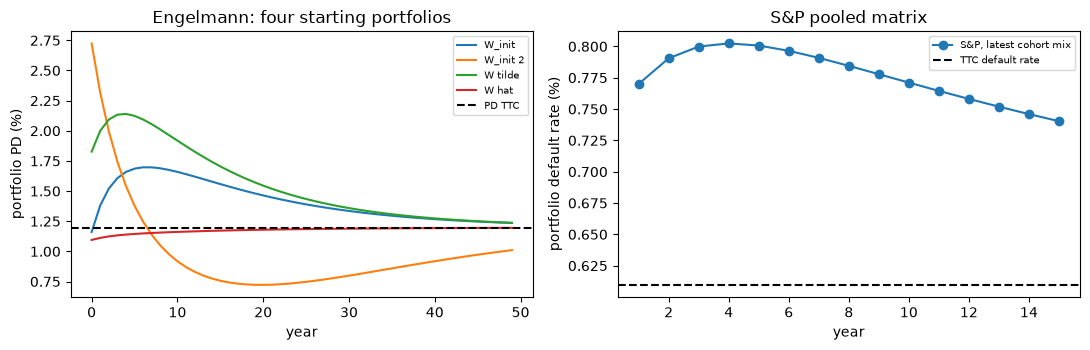

In [10]:
# Draw the four printed paths and the S&P projection against their TTC levels
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for pf in eng["portfolios"]:
    left.plot(range(len(pf["pd_path"])), 100 * np.array(pf["pd_path"]), label=pf["name"])
left.axhline(100 * ttc_printed["recomputed"], color="black", linestyle="--", label="PD TTC")
left.set_xlabel("year")
left.set_ylabel("portfolio PD (%)")
left.set_title("Engelmann: four starting portfolios")
left.legend(fontsize=7)
right.plot(range(1, 16), 100 * rates, marker="o", label="S&P, latest cohort mix")
right.axhline(100 * path["ttc"]["default_rate"], color="black", linestyle="--", label="TTC default rate")
right.set_xlabel("year")
right.set_ylabel("portfolio default rate (%)")
right.set_title("S&P pooled matrix")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **The tail, not the average.** The S&P through-the-cycle PD of the cohort mix is 0.61% and the Basel III corporate correlation at that PD 0.21. The LHP default rate is 0.24% in the median year, 1.54% in a 90% year, 5.23% in a 99% year and 10.9% in a 99.9% year, 17.9 times the PD. The latest cohort's 0.77% implies a credit-cycle factor of -0.77.
- **One exposure.** At PD 1%, LGD 45% and maturity 2.5 years the correlation is 0.1928, the 99.9% conditional PD 14.03% (the LHP quantile, equal to the Vasicek conditional PD), the maturity adjustment 1.2598, K 0.07385 and the risk weight 92.3%: 7.385 of capital per 100 of exposure. K rebuilt from the LHP quantile equals the engine's.
- **Regimes.** At PDs of 0.04%, 1% and 10% the risk weights are 19.65%, 92.32% and 193.1% under Basel III final, the same under CRR3, and 18.21%, 97.86% and 204.7% under Basel II. Above the floors Basel II is exactly 1.06 times Basel III; at 0.04%, between the two floors (0.03% and 0.05%), it is 0.927 times. RAN 21-6 gives the Basel III number for this corporate exposure. The 162 committed retail weights of case C01 equal the engine's recomputation exactly; a QRRE revolver at PD 2% and LGD 50% weighs 32.14% under Basel III and CRR3 and 34.06% under Basel II.
- **From PDs to a portfolio.** The floor binds for AAA, AA and A under both definitions. The cohort mix has an average risk weight of 57.97% with the default-page PDs (`d2`) and 47.45% with the transition-page PDs (`d4`), equal to the committed values; the second is 0.819 times the first, the subject of notebook 10.
- **The drift.** Engelmann's printed paths: three of four starting portfolios reach the TTC PD (1.198% printed, 1.1976% recomputed) by a non-monotone path. One starts at 1.161%, rises to 1.697% in year 6 and ends at 1.236% after 50 years; one starts at 2.724%, falls to 0.722% in year 20 and rises to 1.010%; one starts at 1.827%, rises to 2.14% in year 4 and falls to 1.237%. On the S&P matrix the default rate of the latest cohort's mix starts at 0.770%, rises to 0.802% in year 4 and is 0.740% in year 15, still above the TTC rate of 0.610%.

What this notebook does not show: the Basel III output floor and the standardised approach (outside this product's IRB cases), or how the choice of PD moves capital across calibration approaches (notebook 09).

## Summary

- The IRB risk weight is the loss in a 99.9% year of a large homogeneous portfolio less the expected loss, with a maturity adjustment; the engine's two modules (IRB and Vasicek) agree on it.
- Regimes differ by the PD floor and by the 1.06 factor of Basel II; Basel III final and CRR3 give the same weight on a corporate exposure.
- A long-run PD below the floor weighs as the floor, and the definition of default moves a portfolio's weight by 18%.
- A projection by a migration matrix drifts to a portfolio of its own and its PD can rise and fall on the way: a spurious cycle.

**What to try next.** Change the LGD of Step 2 to 0.40 and the maturity to 1 and 5 years and read how K moves; then read notebook 08.

## References

- BCBS, Basel Framework, CRE31 (IRB approach: risk-weight functions) and CRE32 (risk components: LGD, maturity, PD floor), and CRE30.4 for the Basel II scaling factor. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), doi 10.1016/S1042-9573(03)00040-8.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, equations 9 and 10, Theorem 1 and section 4.
- Regulation (EU) 2024/1623 (CRR3), Article 153, for the EU regime.